In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("/home/shamim/ML/House_price_perdiction/train.csv")

# First 5 rows
print(df.head())

# Dataset shape
print("\nShape:", df.shape)

# Dataset information
print("\nInformation:")
print(df.info())

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008        WD   

In [2]:
# Select numerical columns
X = df.select_dtypes(include=np.number)

# Remove target column if present
if 'SalePrice' in X.columns:
    X = X.drop(columns=['SalePrice'])

print("Selected Features:")
print(X.columns.tolist())

print("\nShape:", X.shape)

Selected Features:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']

Shape: (1460, 37)


In [3]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Before Scaling:")
print(X.head())

print("\nAfter Scaling:")
print(X_scaled[:5])

Before Scaling:
    Id  MSSubClass  LotFrontage  LotArea  OverallQual  OverallCond  YearBuilt  \
0  1.0        60.0         65.0   8450.0          7.0          5.0     2003.0   
1  2.0        20.0         80.0   9600.0          6.0          8.0     1976.0   
2  3.0        60.0         68.0  11250.0          7.0          5.0     2001.0   
3  4.0        70.0         60.0   9550.0          7.0          5.0     1915.0   
4  5.0        60.0         84.0  14260.0          8.0          5.0     2000.0   

   YearRemodAdd  MasVnrArea  BsmtFinSF1  ...  GarageArea  WoodDeckSF  \
0        2003.0       196.0       706.0  ...       548.0         0.0   
1        1976.0         0.0       978.0  ...       460.0       298.0   
2        2002.0       162.0       486.0  ...       608.0         0.0   
3        1970.0         0.0       216.0  ...       642.0         0.0   
4        2000.0       350.0       655.0  ...       836.0       192.0   

   OpenPorchSF  EnclosedPorch  3SsnPorch  ScreenPorch  PoolArea 

In [10]:
from sklearn.decomposition import PCA

pca = PCA(n_components=3)

X_pca = pca.fit_transform(X_scaled)

print("Original Shape:", X_scaled.shape)
print("After PCA:", X_pca.shape)

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(sum(pca.explained_variance_ratio_))

Original Shape: (1460, 37)
After PCA: (1460, 3)

Explained Variance Ratio:
[0.19253349 0.0865939  0.06952302]

Total Explained Variance:
0.3486504138054493


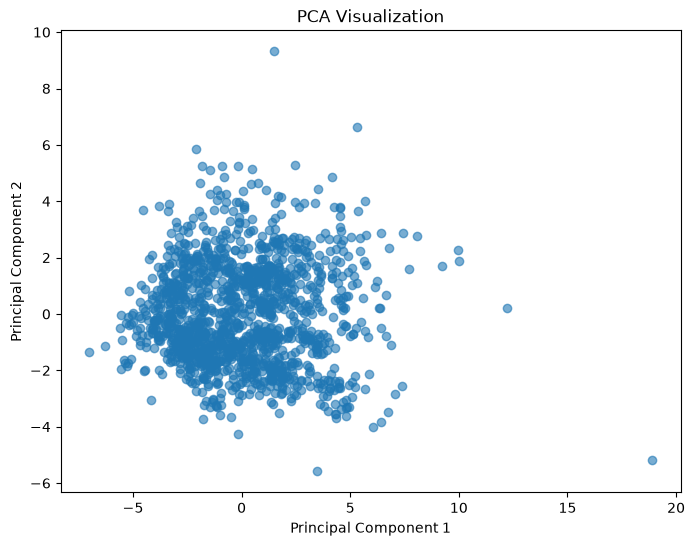

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization")

plt.show()

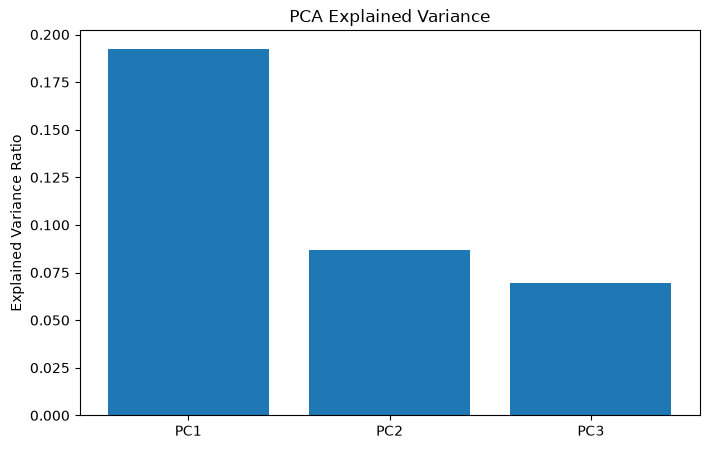

In [13]:
plt.figure(figsize=(8, 5))

plt.bar(
    ['PC1', 'PC2','PC3'],
    pca.explained_variance_ratio_
)

plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")

plt.show()

In [15]:
import pandas as pd
import numpy as np

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor

# Load datasets
train = pd.read_csv("/home/shamim/ML/House_price_perdiction/train.csv")
test = pd.read_csv("/home/shamim/ML/House_price_perdiction/test.csv")

# Separate features and target
X_train = train.drop(columns=['SalePrice', 'Id'])
y_train = train['SalePrice']

X_test = test.drop(columns=['Id'])

# Keep numerical features
X_train = X_train.select_dtypes(include=np.number)
X_test = X_test[X_train.columns]

# Handle missing values
imputer = SimpleImputer(strategy='median')
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Standardization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# PCA
pca = PCA(n_components=3)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

print("Explained Variance:", pca.explained_variance_ratio_.sum())

# Random Forest
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

# Predict house prices
predictions = model.predict(X_test)

# Create submission
submission = pd.DataFrame({
    'Id': test['Id'],
    'SalePrice': predictions
})

submission.to_csv("submission_pca.csv", index=False)

print(submission.head())
print("Submission file created!")

Explained Variance: 0.35831545588439534
     Id   SalePrice
0  1461  122288.625
1  1462  155150.000
2  1463  195370.700
3  1464  204275.410
4  1465  165548.935
Submission file created!
